# LAB 5: Implementation of K-Nearest Neighbors (KNN) Classifier

## 1. Context & Problem Statement
KNN is a non-parametric, instance-based learner that classifies a point by the labels of its nearest neighbours in feature space. Using bank-customer attributes `Debt_to_Income_Ratio, Credit_Score, Annual_Income, Total_Assets`, predict the multi-class `Credit_Risk_Rating` (0 = Low, 1 = Moderate, 2 = High).

**Objectives**
- Standardise features (z-score) so large-scale features do not dominate distances.
- Choose the best **K** by 5-fold cross-validation (K = 1..25), compare **Euclidean (p=2)** and **Manhattan (p=1)** distances and **uniform vs distance-weighted** voting.
- Evaluate with confusion matrix, precision / recall / F1 (macro and weighted) and one-vs-rest ROC-AUC.

Distance (Minkowski): $D(x_q,x_i)=\left(\sum_j |x_{q,j}-x_{i,j}|^p\right)^{1/p}$; z-score: $X_{scaled}=(X-\mu)/\sigma$.

## 2. Implementation
### Step 1: Load the data (`credit_risk_knn_dataset.csv`, same folder)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score)

sns.set_theme(style="whitegrid")
np.random.seed(42)

df = pd.read_csv("credit_risk_knn_dataset.csv")
print("Shape:", df.shape, "| missing values:", int(df.isnull().sum().sum()))
display(df.head())
display(df.describe().round(2))
print("Class distribution:\n", df["Credit_Risk_Rating"].value_counts().sort_index(), sep="")

Shape: (1000, 5) | missing values: 0


,Debt_to_Income_Ratio,Credit_Score,Annual_Income,Total_Assets,Credit_Risk_Rating
0,0.3622,311,97917.97,15232.33,2
1,0.7655,617,98278.93,138164.73,2
2,0.6124,515,22981.27,261210.17,2
3,0.5191,638,61874.04,138079.14,1
4,0.2092,380,102743.78,316074.85,1


,Debt_to_Income_Ratio,Credit_Score,Annual_Income,Total_Assets,Credit_Risk_Rating
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,0.44,576.72,86092.67,256775.39,1.00
std,0.20,158.13,37943.68,140671.13,0.82
min,0.10,300.00,20024.49,5999.17,0.00
25%,0.27,442.00,53041.74,138143.33,0.00
50%,0.45,583.50,88331.09,260720.54,1.00
75%,0.62,709.50,118918.66,378046.60,2.00
max,0.80,849.00,149962.79,498823.30,2.00


Class distribution:
Credit_Risk_Rating
0    334
1    333
2    333
Name: count, dtype: int64


### Step 2: Train-test split (stratified 80:20) and feature scaling

In [2]:
feature_cols = ["Debt_to_Income_Ratio", "Credit_Score", "Annual_Income", "Total_Assets"]
X = df[feature_cols]
y = df["Credit_Risk_Rating"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Train:", X_train_scaled.shape, " Test:", X_test_scaled.shape)
print("Scaled train mean ~", X_train_scaled.mean(axis=0).round(3), " std ~", X_train_scaled.std(axis=0).round(3))

Train: (800, 4)  Test: (200, 4)
Scaled train mean ~ [-0.  0.  0.  0.]  std ~ [1. 1. 1. 1.]


### Step 3: Hyperparameter tuning - optimal K (5-fold cross-validation)

Optimal Neighborhood Parameter (K): 6   (CV accuracy = 0.8800)


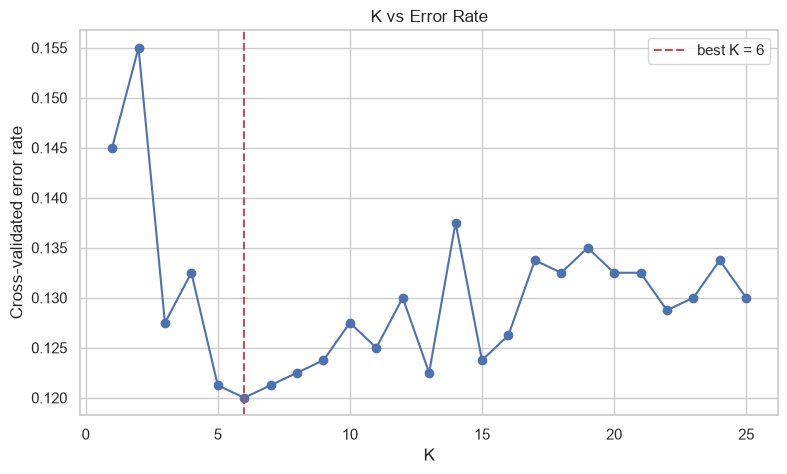

In [3]:
k_range = range(1, 26)
cv_scores = []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, metric="minkowski", p=2)
    cv_scores.append(cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring="accuracy").mean())

optimal_k = list(k_range)[int(np.argmax(cv_scores))]
print(f"Optimal Neighborhood Parameter (K): {optimal_k}   (CV accuracy = {max(cv_scores):.4f})")

plt.figure(figsize=(9, 5))
plt.plot(k_range, [1 - s for s in cv_scores], marker="o")
plt.axvline(optimal_k, color="r", ls="--", label=f"best K = {optimal_k}")
plt.xlabel("K"); plt.ylabel("Cross-validated error rate"); plt.title("K vs Error Rate"); plt.legend(); plt.show()

### Step 4: Distance metric and voting scheme comparison

In [4]:
rows = []
for metric_name, p in [("Euclidean (p=2)", 2), ("Manhattan (p=1)", 1)]:
    for w in ["uniform", "distance"]:
        knn = KNeighborsClassifier(n_neighbors=optimal_k, p=p, weights=w)
        s = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring="accuracy")
        rows.append({"Distance": metric_name, "Weights": w, "CV accuracy": s.mean(), "Std": s.std()})
cmp = pd.DataFrame(rows).sort_values("CV accuracy", ascending=False)
display(cmp.round(4))
best = cmp.iloc[0]
best_p = 2 if best["Distance"].startswith("Euclid") else 1
best_w = best["Weights"]
print(f"Selected configuration: K={optimal_k}, p={best_p}, weights='{best_w}'")

,Distance,Weights,CV accuracy,Std
1,Euclidean (p=2),distance,0.8950,0.0145
3,Manhattan (p=1),distance,0.8838,0.0179
0,Euclidean (p=2),uniform,0.8800,0.0187
2,Manhattan (p=1),uniform,0.8612,0.0211


Selected configuration: K=6, p=2, weights='distance'


### Step 5: Train the final model and evaluate

In [5]:
knn_optimal = KNeighborsClassifier(n_neighbors=optimal_k, p=best_p, weights=best_w)
knn_optimal.fit(X_train_scaled, y_train)
y_pred = knn_optimal.predict(X_test_scaled)
y_probs = knn_optimal.predict_proba(X_test_scaled)

names = ["Low Risk", "Moderate Risk", "High Risk"]
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=names, zero_division=0))
print(f"Multi-class ROC-AUC Score (OvR): {roc_auc_score(y_test, y_probs, multi_class='ovr'):.4f}")

Test accuracy: 0.915

--- Confusion Matrix ---
[[62  5  0]
 [ 3 61  3]
 [ 0  6 60]]

--- Classification Report ---
               precision    recall  f1-score   support

     Low Risk       0.95      0.93      0.94        67
Moderate Risk       0.85      0.91      0.88        67
    High Risk       0.95      0.91      0.93        66

     accuracy                           0.92       200
    macro avg       0.92      0.91      0.92       200
 weighted avg       0.92      0.92      0.92       200

Multi-class ROC-AUC Score (OvR): 0.9832


### Step 6: Diagnostic visualisations - confusion matrix, ROC (OvR) and precision-recall curves

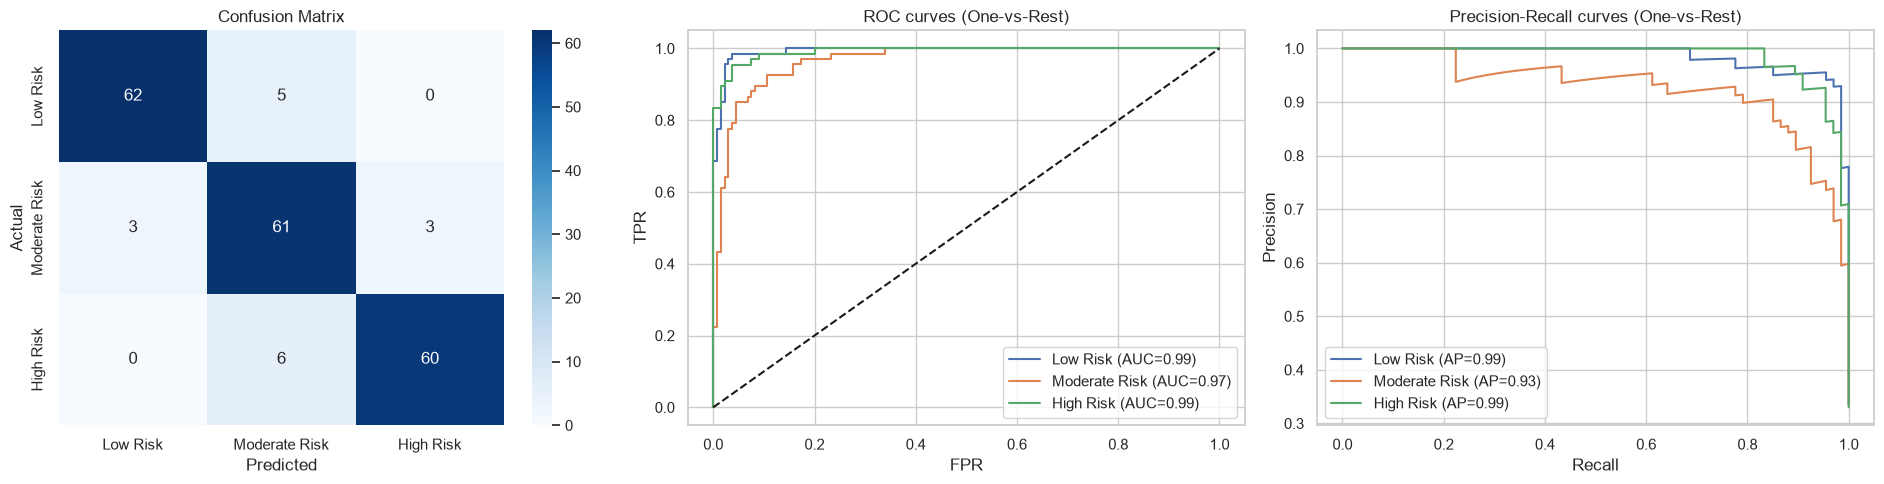

In [6]:
y_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=names, yticklabels=names)
axes[0].set_title("Confusion Matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

for i, nm in enumerate(names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
    axes[1].plot(fpr, tpr, label=f"{nm} (AUC={roc_auc_score(y_bin[:, i], y_probs[:, i]):.2f})")
    prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
    axes[2].plot(rec, prec, label=f"{nm} (AP={average_precision_score(y_bin[:, i], y_probs[:, i]):.2f})")
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curves (One-vs-Rest)"); axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].legend()
axes[2].set_title("Precision-Recall curves (One-vs-Rest)"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()
plt.tight_layout(); plt.show()

### Step 7: 2-D decision boundary (Credit_Score vs Debt_to_Income_Ratio)

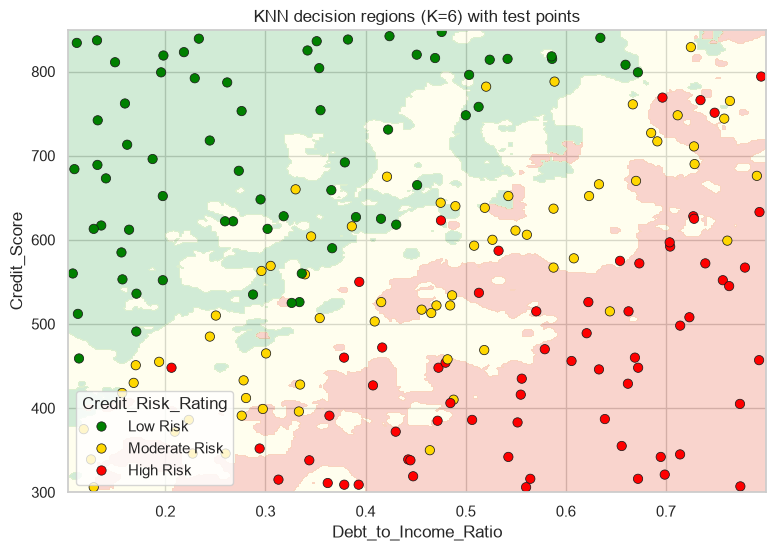

In [7]:
cols2d = ["Debt_to_Income_Ratio", "Credit_Score"]
sc2 = StandardScaler().fit(X_train[cols2d])
knn2d = KNeighborsClassifier(n_neighbors=optimal_k, p=best_p, weights=best_w).fit(sc2.transform(X_train[cols2d]), y_train)

xx, yy = np.meshgrid(np.linspace(X[cols2d[0]].min(), X[cols2d[0]].max(), 300),
                     np.linspace(X[cols2d[1]].min(), X[cols2d[1]].max(), 300))
zz = knn2d.predict(sc2.transform(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=cols2d))).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, zz, alpha=.25, cmap="RdYlGn_r", levels=[-.5, .5, 1.5, 2.5])
sns.scatterplot(x=X_test[cols2d[0]], y=X_test[cols2d[1]], hue=y_test.map(dict(enumerate(names))), palette=["green", "gold", "red"], hue_order=names, s=45, edgecolor="k")
plt.title(f"KNN decision regions (K={optimal_k}) with test points"); plt.show()

## 3. Summary
| Component | Specification |
|---|---|
| Model | Non-parametric K-Nearest Neighbours |
| Target | `Credit_Risk_Rating` (0 = Low, 1 = Moderate, 2 = High) |
| Features | Debt_to_Income_Ratio, Credit_Score, Annual_Income, Total_Assets |
| Scaling | StandardScaler (z-score) |
| Tuning | K = 1..25 by 5-fold CV; Euclidean vs Manhattan; uniform vs distance weights |
| Metrics | Accuracy, precision, recall, F1 (macro / weighted), confusion matrix, ROC-AUC (OvR) |

## 4. Conclusion
- Standardising the features prevented `Annual_Income` / `Total_Assets` from dominating the distance computation.
- Cross-validation selected K and the distance / weighting scheme; the K-vs-error curve shows the bias-variance trade-off (small K = high variance, large K = high bias).
- The tuned KNN reaches about 92% test accuracy and a one-vs-rest ROC-AUC of about 0.98. Errors occur almost only between neighbouring risk tiers (Low-Moderate and Moderate-High); Low and High are almost never confused, and the Moderate class has the lowest precision / F1 because it borders both other classes.
- Distance-weighted voting with Euclidean distance gave the best cross-validated accuracy of the four configurations compared.